CYBERGUARD AI — TASK 9 EDA
Original official training data: (175341, 45)
EDA training subset: (140145, 42)
Held-out validation rows: 35196
Numerical columns: 39
Categorical columns: ['proto', 'service', 'state']


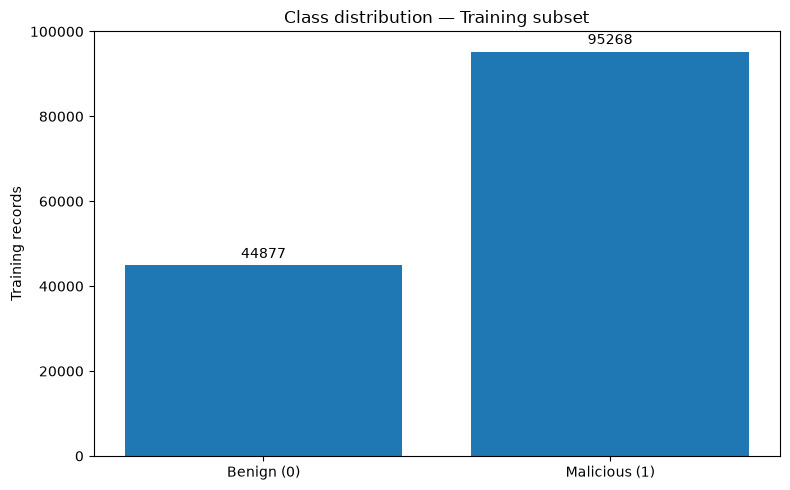

Saved: assets/eda/class_distribution.png


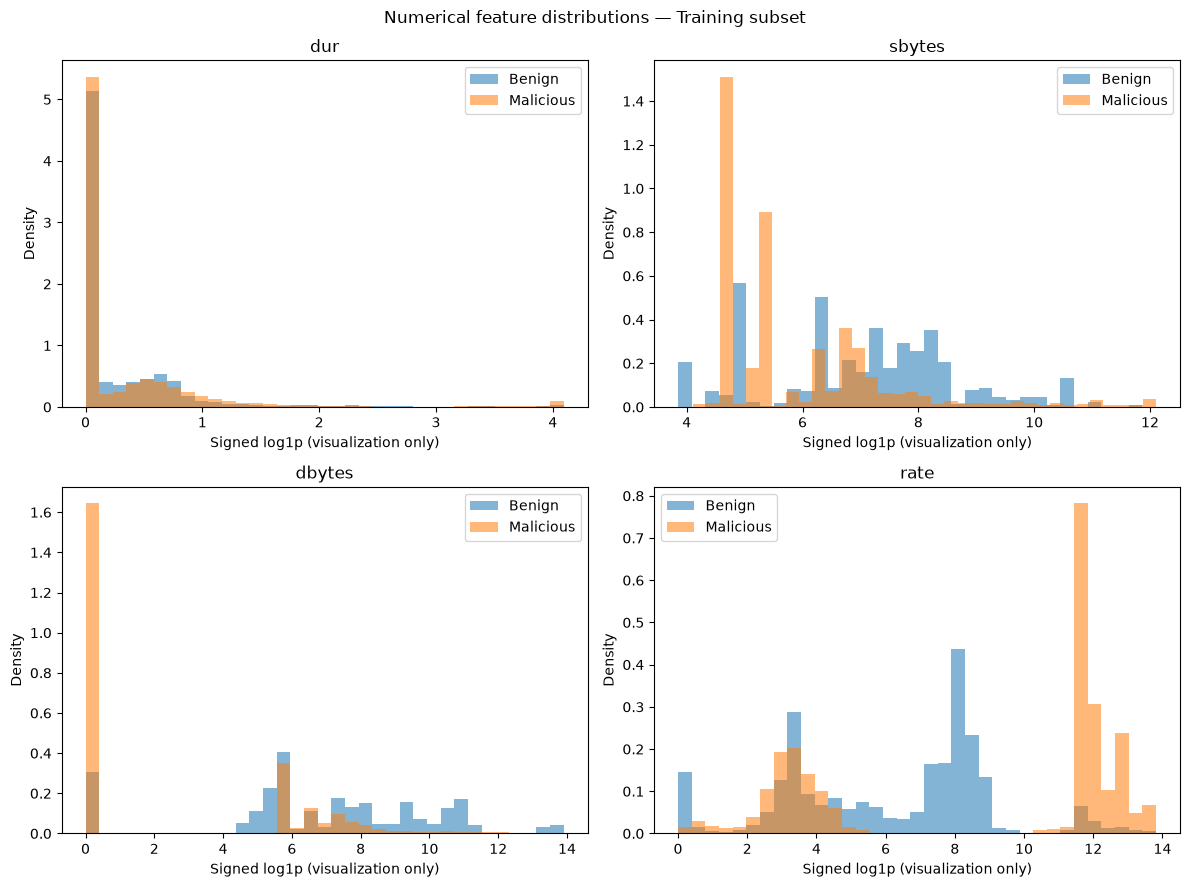

Saved: assets/eda/numerical_distributions.png


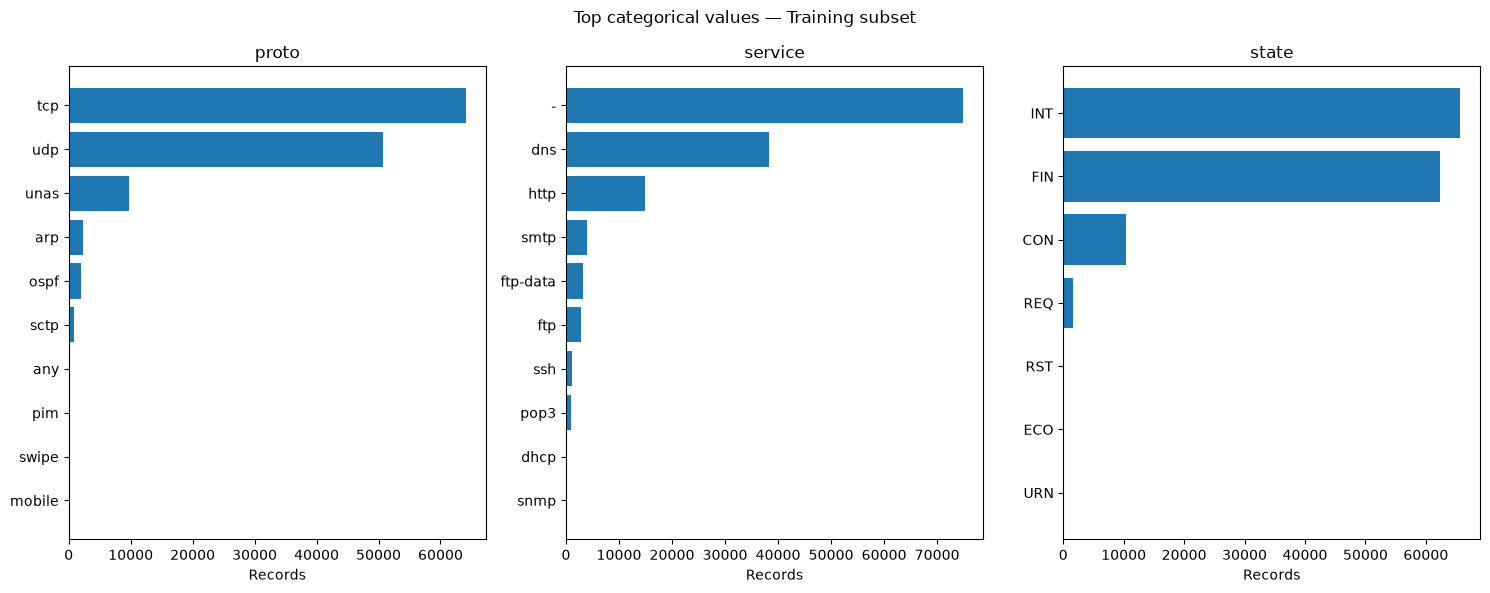

Saved: assets/eda/categorical_features.png


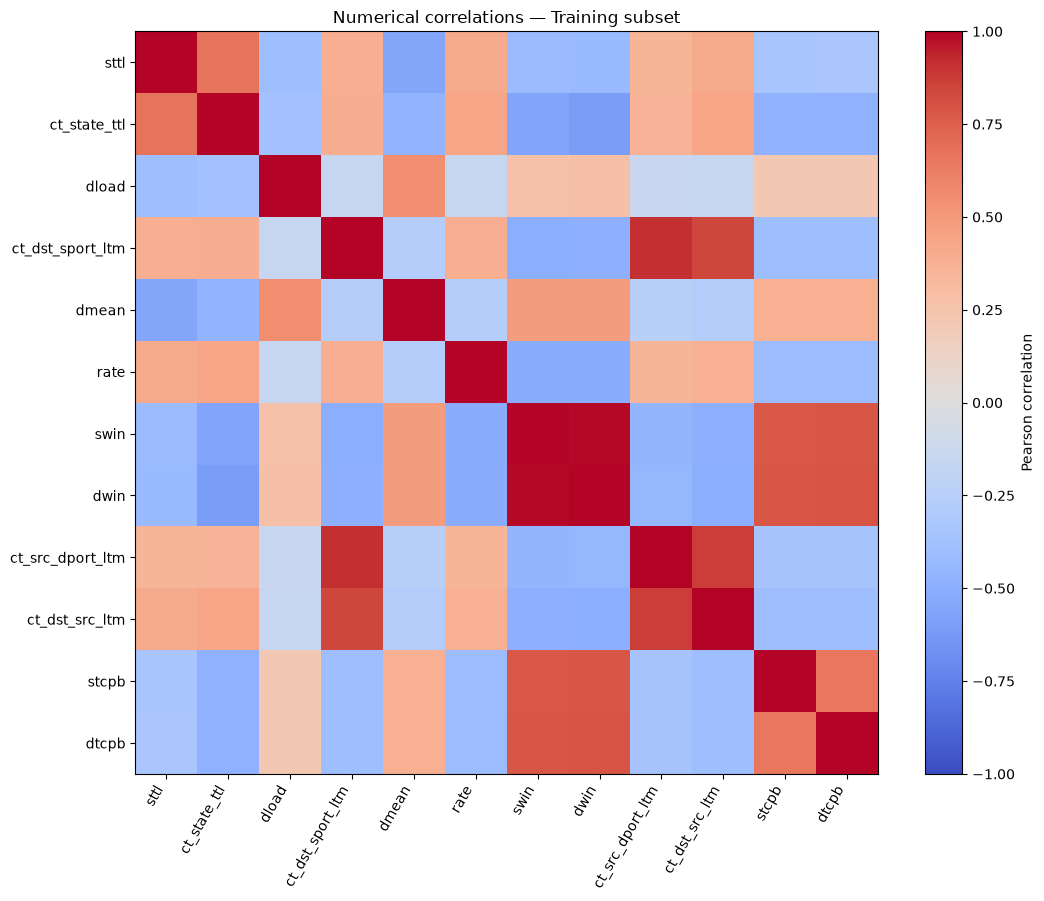

Saved: assets/eda/correlation_matrix.png


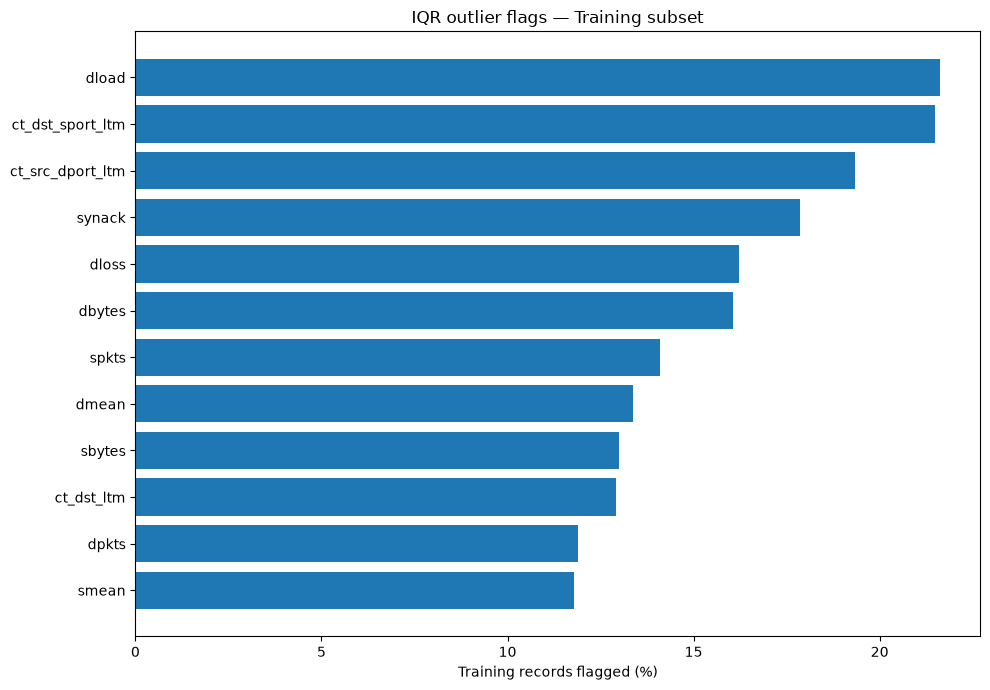

Saved: assets/eda/outlier_analysis.png

EDA FINISHED — TASK 9
Report: docs/eda-report.md
Charts: assets/eda (5 PNG files)
Class distribution: 44,877 benign / 95,268 malicious
Top absolute target correlations:
sttl                0.6918
ct_state_ttl        0.5759
dload              -0.3936
ct_dst_sport_ltm    0.3634
dmean              -0.3417


In [2]:
# ============================================================
# CYBERGUARD AI | TASK 9: EXPLORATORY DATA ANALYSIS (EDA)
# Python 3.11 compatible; uses existing project libraries.
# Analyze ONLY the model-fitting subset of official training data.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit

SEED = 42
CSV_NAME = "UNSW_NB15_training-set.csv"

# 1) Find the project root whether Jupyter starts in the repo or notebooks/.
current = Path.cwd().resolve()
root = next(
    (p for p in (current, *current.parents)
     if (p / "Data" / "Raw data" / CSV_NAME).is_file()),
    None,
)
if root is None:
    raise FileNotFoundError(
        f"Could not locate Data/Raw data/{CSV_NAME}. "
        "Open VS Code in your cyberguard-ai-repo folder."
    )

figures_dir = root / "assets" / "eda"
reports_dir = root / "docs"
figures_dir.mkdir(parents=True, exist_ok=True)
reports_dir.mkdir(parents=True, exist_ok=True)

# 2) Load original training CSV and reproduce Task 10's split.
df = pd.read_csv(root / "Data" / "Raw data" / CSV_NAME)
if "label" not in df.columns:
    raise ValueError("The CSV must contain the binary target column 'label'.")

X = df.drop(columns=["id", "attack_cat", "label"], errors="ignore")
y = pd.to_numeric(df["label"], errors="raise").astype(int)
if not set(y.unique()).issubset({0, 1}):
    raise ValueError("Expected only 0 (Benign) and 1 (Malicious).")

feature_groups = pd.util.hash_pandas_object(X, index=False)
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
training_indices, validation_indices = next(splitter.split(X, y, groups=feature_groups))

X_train = X.iloc[training_indices].copy()
y_train = y.iloc[training_indices].copy()

category_names = [c for c in ("proto", "service", "state") if c in X_train.columns]
numerical = (
    X_train.select_dtypes(include="number")
    .replace([np.inf, -np.inf], np.nan)
)
if numerical.empty or numerical.shape[1] == 0:
    raise ValueError("No numerical columns found to analyze.")

print("CYBERGUARD AI — TASK 9 EDA")
print("Original official training data:", df.shape)
print("EDA training subset:", X_train.shape)
print("Held-out validation rows:", len(validation_indices))
print("Numerical columns:", numerical.shape[1])
print("Categorical columns:", category_names)


def save_figure(fig, name):
    fig.tight_layout()
    destination = figures_dir / name
    fig.savefig(destination, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved:", destination.relative_to(root))


def category_series(column):
    return X_train[column].astype("string").fillna("Missing")


# 3) CLASS DISTRIBUTION
count_0 = int((y_train == 0).sum())
count_1 = int((y_train == 1).sum())
malicious_pct = 100 * count_1 / len(y_train)
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(["Benign (0)", "Malicious (1)"], [count_0, count_1])
ax.bar_label(bars, padding=3)
ax.set_ylabel("Training records")
ax.set_title("Class distribution — Training subset")
save_figure(fig, "class_distribution.png")


# 4) NUMERICAL DISTRIBUTIONS, sampled only for faster plotting.
preferred = ["dur", "sbytes", "dbytes", "rate"]
selected = [c for c in preferred if c in numerical.columns]
selected.extend(c for c in numerical.columns if c not in selected)
selected = selected[:4]

sample_rows = X_train.sample(n=min(30000, len(X_train)), random_state=SEED).index
sample_num = numerical.loc[sample_rows]
sample_labels = y_train.loc[sample_rows]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, feature in zip(axes.flat, selected):
    full_sample = sample_num[feature].dropna()
    if full_sample.empty:
        ax.text(0.5, 0.5, "No valid values", ha="center", va="center")
    else:
        limit = float(full_sample.abs().quantile(0.995))
        for label, name in ((0, "Benign"), (1, "Malicious")):
            values = sample_num.loc[sample_labels == label, feature].dropna()
            if values.empty:
                continue
            clipped = values.clip(-limit, limit)
            transformed = np.sign(clipped) * np.log1p(np.abs(clipped))
            ax.hist(transformed, bins=35, density=True, alpha=0.55, label=name)
        ax.legend()
    ax.set_title(feature)
    ax.set_xlabel("Signed log1p (visualization only)")
    ax.set_ylabel("Density")
for ax in list(axes.flat)[len(selected):]:
    ax.axis("off")
fig.suptitle("Numerical feature distributions — Training subset")
save_figure(fig, "numerical_distributions.png")


# 5) CATEGORICAL FEATURE FREQUENCIES
if category_names:
    fig, axes = plt.subplots(1, len(category_names), figsize=(5 * len(category_names), 6), squeeze=False)
    for ax, feature in zip(axes.flat, category_names):
        top = category_series(feature).value_counts().head(10).iloc[::-1]
        ax.barh(top.index.astype(str), top.values)
        ax.set_title(feature)
        ax.set_xlabel("Records")
    fig.suptitle("Top categorical values — Training subset")
else:
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.text(0.5, 0.5, "No categorical features found", ha="center", va="center")
    ax.axis("off")
save_figure(fig, "categorical_features.png")


# 6) NUMERICAL FEATURE CORRELATIONS
# Target correlations are descriptive, calculated ONLY on training data.
with_target = numerical.corrwith(y_train).dropna()
leading = with_target.abs().nlargest(12).index.tolist()
if leading:
    correlation_matrix = numerical[leading].corr()
    fig, ax = plt.subplots(figsize=(11, 9))
    im = ax.imshow(correlation_matrix, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(np.arange(len(leading)))
    ax.set_yticks(np.arange(len(leading)))
    ax.set_xticklabels(leading, rotation=60, ha="right")
    ax.set_yticklabels(leading)
    fig.colorbar(im, ax=ax, label="Pearson correlation")
    ax.set_title("Numerical correlations — Training subset")
else:
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.text(0.5, 0.5, "No usable correlations", ha="center", va="center")
    ax.axis("off")
save_figure(fig, "correlation_matrix.png")


# 7) OUTLIER FLAGS USING THE IQR RULE (descriptive, not removal)
q1 = numerical.quantile(0.25)
q3 = numerical.quantile(0.75)
iqr = q3 - q1
eligible = iqr[iqr > 0].index
if len(eligible):
    flags = numerical[eligible].lt(q1[eligible] - 1.5 * iqr[eligible]) | numerical[eligible].gt(q3[eligible] + 1.5 * iqr[eligible])
    outlier_percent = (flags.sum() / len(numerical) * 100).sort_values(ascending=False)
else:
    outlier_percent = pd.Series(dtype=float)

fig, ax = plt.subplots(figsize=(10, 7))
if not outlier_percent.empty:
    top = outlier_percent.head(12).iloc[::-1]
    ax.barh(top.index, top.values)
    ax.set_xlabel("Training records flagged (%)")
else:
    ax.text(0.5, 0.5, "No eligible features (IQR > 0)", ha="center", va="center")
    ax.axis("off")
ax.set_title("IQR outlier flags — Training subset")
save_figure(fig, "outlier_analysis.png")


# 8) WRITE MARKDOWN REPORT (no f-string backslash expressions / tabulate)
report_lines = [
    "# CyberGuard AI — Exploratory Data Analysis Report",
    "",
    "## 1. Scope",
    "Exploratory analysis of the model-fitting portion of the official UNSW-NB15 training CSV.",
    "The held-out validation subset and official test CSV are not analyzed here.",
    "The training/validation split uses GroupShuffleSplit with the same settings as Task 10.",
    "",
    "## 2. Dataset Summary",
    f"- Original official training rows: {len(df):,}",
    f"- EDA training rows: {len(X_train):,}",
    f"- Held-out validation rows: {len(validation_indices):,}",
    f"- Selected input features: {X_train.shape[1]}",
    f"- Numerical features: {numerical.shape[1]}",
    f"- Categorical features: {len(category_names)}",
    f"- Missing cells (NaN): {int(X_train.isna().sum().sum()):,}",
    "",
    "## 3. Class Distribution",
    f"- Benign: {count_0:,}",
    f"- Malicious: {count_1:,}",
    f"- Malicious proportion: {malicious_pct:.2f}%",
    "![Class Distribution](../assets/eda/class_distribution.png)",
    "",
    "## 4. Numerical Distributions",
    "Selected numerical features are displayed on a signed log1p scale, with sampled values clipped",
    "at the 99.5th percentile of absolute magnitude for readability. Raw data is unchanged.",
    "![Numerical Distributions](../assets/eda/numerical_distributions.png)",
    "",
    "## 5. Categorical Features",
    "Frequencies below describe the top values of each available categorical feature.",
    "The literal '-' service value is preserved, not automatically considered missing.",
]
for feature in category_names:
    report_lines.extend(["", f"### {feature}", "", "| Value | Records |", "|---|---:|"])
    for name, amount in category_series(feature).value_counts().head(5).items():
        report_lines.append(f"| {str(name).replace('|', '/')} | {int(amount):,} |")
report_lines.extend([
    "", "![Categorical Features](../assets/eda/categorical_features.png)",
    "", "## 6. Numerical Correlations",
    "Ranked by absolute Pearson correlation with the target within the training subset.",
    "Correlation is not causation or Random Forest feature importance.",
    "", "| Feature | Correlation with label |", "|---|---:|",
])
for feature in leading:
    report_lines.append(f"| {feature} | {with_target[feature]:.4f} |")
report_lines.extend([
    "", "![Correlation Matrix](../assets/eda/correlation_matrix.png)",
    "", "## 7. IQR Outlier Analysis",
    "Flags indicate values outside Q1 − 1.5×IQR or Q3 + 1.5×IQR.",
    "Features with IQR=0 are excluded from this outlier estimate.",
    "", "| Feature | Flagged records (%) |", "|---|---:|",
])
for feature, percentage in outlier_percent.head(12).items():
    report_lines.append(f"| {feature} | {percentage:.2f}% |")
report_lines.extend([
    "", "![Outlier Analysis](../assets/eda/outlier_analysis.png)",
    "", "## 8. Interpretation and Limitations",
    "- This historical dataset is not representative of every real-world network.",
    "- Labels and observations may contain duplicates or inconsistencies.",
    "- Extreme feature values may be valid traffic, not necessarily data errors.",
    "- No records were removed based on these EDA visualizations.",
    "- The previously trained model was NOT adjusted using these retrospective findings.",
    "- Prior validation/test metrics are unchanged; known Train/Test overlap remains a limitation.",
    "", "## 9. Conclusion",
    "This EDA documents class balance, numerical and categorical distributions,",
    "correlation structure, and outlier flags using training data only.",
    "",
])
report_path = reports_dir / "eda-report.md"
report_path.write_text("\n".join(report_lines), encoding="utf-8")

print("\n" + "=" * 45)
print("EDA FINISHED — TASK 9")
print("=" * 45)
print("Report:", report_path.relative_to(root))
print("Charts:", figures_dir.relative_to(root), "(5 PNG files)")
print(f"Class distribution: {count_0:,} benign / {count_1:,} malicious")
print("Top absolute target correlations:")
print(with_target.reindex(leading).head(5).round(4).to_string())
